# Limpieza y preparación — House Prices

Implementa las decisiones del notebook [`1.0-dg-analisis-exploratorio`](1.0-dg-analisis-exploratorio.ipynb):
imputación de faltantes, codificación de ordinales, tratamiento de outliers y descarte de
columnas casi constantes.

**Entrada:** `data/raw/{train,test}.csv` · **Salida:** `data/interim/{train,test}_limpio.csv`

Va a `interim` y no a `processed` porque aún falta el feature engineering; `processed`
queda para el dataset final de modelado.

## Regla que se respeta en todo el notebook

**Todo valor de imputación se calcula solo con `train` y se aplica a ambos.** Usar la mediana
del conjunto combinado metería información de test en el entrenamiento (fuga de datos) y
las métricas de validación saldrían optimistas.

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

try:
    from house_pricing.config import INTERIM_DATA_DIR, RAW_DATA_DIR
except ModuleNotFoundError:
    PROJ_ROOT = Path.cwd().parent
    RAW_DATA_DIR = PROJ_ROOT / "data" / "raw"
    INTERIM_DATA_DIR = PROJ_ROOT / "data" / "interim"

pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 160)

SURFACE, INK, INK_MUTED, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e5e4e0"
BLUE, RED = "#2a78d6", "#e34948"

plt.rcParams.update(
    {
        "figure.figsize": (8, 4.5),
        "figure.dpi": 110,
        "figure.facecolor": SURFACE,
        "axes.facecolor": SURFACE,
        "axes.edgecolor": GRID,
        "axes.labelcolor": INK_MUTED,
        "axes.titlecolor": INK,
        "axes.titlesize": 11,
        "axes.titleweight": "bold",
        "axes.titlelocation": "left",
        "axes.titlepad": 12,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "grid.color": GRID,
        "grid.linewidth": 0.8,
        "xtick.color": INK_MUTED,
        "ytick.color": INK_MUTED,
        "text.color": INK,
        "font.size": 9,
        "lines.linewidth": 2,
        "legend.frameon": False,
    }
)

In [3]:
train = pd.read_csv(RAW_DATA_DIR / "train.csv")
test = pd.read_csv(RAW_DATA_DIR / "test.csv")

print(f"train {train.shape} · test {test.shape}")
print(f"faltantes totales — train: {int(train.isna().sum().sum())} · test: {int(test.isna().sum().sum())}")

train (1460, 81) · test (1459, 80)
faltantes totales — train: 7829 · test: 7878


## 1. Outliers: se eliminan dos filas, no cuatro

El EDA mostró 4 casas con `GrLivArea > 4000`. No son equivalentes:

| Id | GrLivArea | OverallQual | SaleCondition | SalePrice | decisión |
|----|-----------|-------------|---------------|-----------|----------|
| 524 | 4676 | 10 | `Partial` | 184 750 | **eliminar** |
| 1299 | 5642 | 10 | `Partial` | 160 000 | **eliminar** |
| 692 | 4316 | 10 | `Normal` | 755 000 | conservar |
| 1183 | 4476 | 10 | `Abnorml` | 745 000 | conservar |

524 y 1299 son casas enormes de calidad 10 vendidas por menos de 200 mil con
`SaleCondition = Partial` (obra no terminada al momento de la venta): el precio no refleja el
inmueble, así que son ruido para el modelo. 692 y 1183 son caras *y* grandes — coherentes con
la tendencia y valiosas porque sostienen el extremo superior del rango.

Se eliminan **solo de train**. En test nunca se borran filas: hay que predecir las 1459.

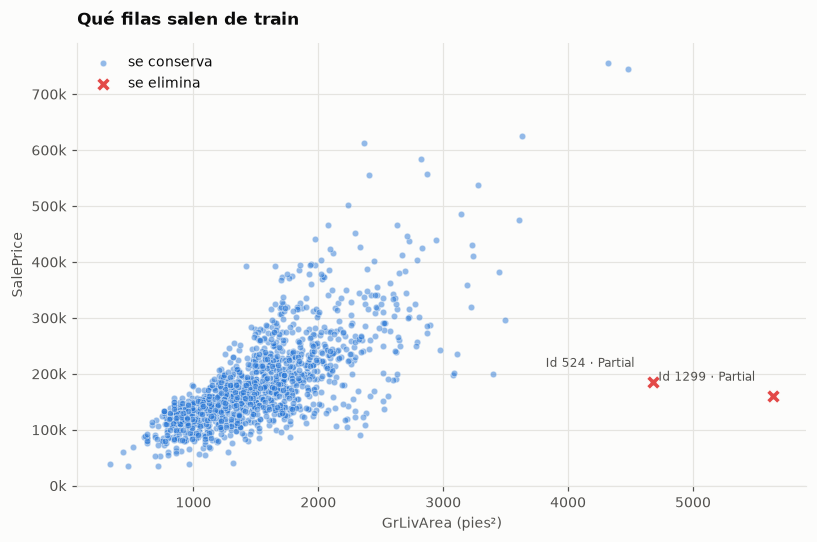

In [4]:
IDS_OUTLIERS = [524, 1299]

fig, ax = plt.subplots(figsize=(7.5, 5))

resto = train[~train["Id"].isin(IDS_OUTLIERS)]
ax.scatter(
    resto["GrLivArea"], resto["SalePrice"],
    s=18, marker="o", color=BLUE,
    alpha=0.5, edgecolor=SURFACE, linewidth=0.5, label="se conserva",
)

fuera = train[train["Id"].isin(IDS_OUTLIERS)]
ax.scatter(
    fuera["GrLivArea"], fuera["SalePrice"],
    s=90, marker="X", color=RED, edgecolor=SURFACE, linewidth=1, label="se elimina",
)

ax.set_title("Qué filas salen de train")
ax.set_xlabel("GrLivArea (pies²)")
ax.set_ylabel("SalePrice")
ax.yaxis.set_major_formatter(lambda v, _: f"{v / 1000:.0f}k")
ax.set_axisbelow(True)
ax.legend(loc="upper left")

# Forma de marcador y etiqueta directa: la identidad no depende solo del color.
for _, f in fuera.iterrows():
    ax.annotate(
        f"Id {int(f['Id'])} · {f['SaleCondition']}",
        (f["GrLivArea"], f["SalePrice"]),
        textcoords="offset points", xytext=(-12, 10), ha="right",
        fontsize=8, color=INK_MUTED,
    )

fig.tight_layout()

In [5]:
antes = len(train)
train = train[~train["Id"].isin(IDS_OUTLIERS)].reset_index(drop=True)
print(f"train: {antes} -> {len(train)} filas ({antes - len(train)} eliminadas)")

train: 1460 -> 1458 filas (2 eliminadas)


## 2. Faltantes estructurales vs. faltantes reales

La distinción es lo central de este dataset. `data_description.txt` dice, por ejemplo, que
en `PoolQC` el valor `NA` significa *"No Pool"*: no es un dato perdido, es **ausencia de la
característica**. Imputarlo con la moda inventaría piscinas.

- **Estructural, categórica** → categoría `"None"` (o `0` si ya la codificamos como ordinal).
- **Estructural, numérica** → `0` (sin sótano ⇒ 0 pies² de sótano).
- **Real** → mediana o moda calculada en train.

Y un detalle que vimos en el EDA: **16 columnas tienen faltantes solo en test**
(`MSZoning`, `Functional`, `KitchenQual`, `Exterior1st`…). No se pueden ignorar ni eliminar
esas filas; hay que imputarlas con estadísticos de train.

In [6]:
# NA = ausencia de la característica. Verificado contra data/raw/data_description.txt.
ESTRUCTURAL_CAT = [
    "Alley", "BsmtQual", "BsmtCond", "BsmtExposure", "BsmtFinType1", "BsmtFinType2",
    "FireplaceQu", "GarageType", "GarageFinish", "GarageQual", "GarageCond",
    "PoolQC", "Fence", "MiscFeature", "MasVnrType",
]
ESTRUCTURAL_NUM = [
    "MasVnrArea", "BsmtFinSF1", "BsmtFinSF2", "BsmtUnfSF", "TotalBsmtSF",
    "BsmtFullBath", "BsmtHalfBath", "GarageCars", "GarageArea",
]

# Faltantes genuinos: alguien no registró el dato.
REAL_MEDIANA_POR_BARRIO = ["LotFrontage"]
REAL_MODA = [
    "Electrical", "MSZoning", "Functional", "KitchenQual", "Exterior1st",
    "Exterior2nd", "SaleType", "Utilities",
]

# GarageYrBlt necesita su propio tratamiento (sección siguiente): no es estructural-0
# ni un faltante real.
APARTE = ["GarageYrBlt"]

print(f"estructurales: {len(ESTRUCTURAL_CAT)} cat + {len(ESTRUCTURAL_NUM)} num")
print(f"reales:        {len(REAL_MEDIANA_POR_BARRIO) + len(REAL_MODA)}")
print(f"caso aparte:   {len(APARTE)}")

# Control: ninguna columna con faltantes debe quedar sin clasificar.
con_faltantes = set(
    pd.concat([train.isna().any(), test.isna().any()], axis=1).any(axis=1).loc[lambda s: s].index
) - {"SalePrice"}
clasificadas = set(
    ESTRUCTURAL_CAT + ESTRUCTURAL_NUM + REAL_MEDIANA_POR_BARRIO + REAL_MODA + APARTE
)
sin_clasificar = con_faltantes - clasificadas
print(f"\ncolumnas con faltantes: {len(con_faltantes)}")
print("sin clasificar:", sin_clasificar or "ninguna ✓")

estructurales: 15 cat + 9 num
reales:        9
caso aparte:   1

columnas con faltantes: 34
sin clasificar: ninguna ✓


### `GarageYrBlt`: el caso que no encaja en ninguna de las dos cajas

Si no hay garaje, el año de construcción del garaje no es 0 ni es un dato perdido: **no
existe**. Poner 0 crearía una casa construida en el año cero y arruinaría cualquier modelo
lineal. La correlación con `YearBuilt` es 0.83, así que se rellena con `YearBuilt` y se añade
un indicador explícito `SinGaraje` para que el modelo pueda distinguir el caso.

In [7]:
def tratar_garage_yr(df: pd.DataFrame) -> tuple[pd.DataFrame, int]:
    """Rellena GarageYrBlt con YearBuilt y marca las casas sin garaje.

    Devuelve el dataframe tratado y cuántos años imposibles se corrigieron.
    """
    df = df.copy()
    df["SinGaraje"] = df["GarageYrBlt"].isna().astype("int8")
    df["GarageYrBlt"] = df["GarageYrBlt"].fillna(df["YearBuilt"])
    # En test hay un registro con GarageYrBlt = 2207: error de captura.
    fuera_rango = df["GarageYrBlt"] > df["YrSold"]
    df.loc[fuera_rango, "GarageYrBlt"] = df.loc[fuera_rango, "YearBuilt"]
    return df, int(fuera_rango.sum())


train, n_tr = tratar_garage_yr(train)
test, n_te = tratar_garage_yr(test)
print(f"años de garaje imposibles corregidos — train: {n_tr} · test: {n_te}")
print(f"casas sin garaje — train: {train['SinGaraje'].sum()} · test: {test['SinGaraje'].sum()}")

años de garaje imposibles corregidos — train: 0 · test: 2
casas sin garaje — train: 81 · test: 78


## 3. Imputación

`LotFrontage` (los metros de fachada) se imputa con la **mediana de su barrio**, no con la
mediana global: el tamaño de lote depende fuertemente del barrio. Los barrios que no tengan
mediana en train caen a la mediana global.

In [8]:
# --- Estadísticos: SOLO de train ---
mediana_frente_barrio = train.groupby("Neighborhood")["LotFrontage"].median()
mediana_frente_global = train["LotFrontage"].median()
modas = {c: train[c].mode(dropna=True).iloc[0] for c in REAL_MODA}

pd.Series(modas, name="moda en train").to_frame()

,moda en train
Electrical,SBrkr
MSZoning,RL
Functional,Typ
KitchenQual,TA
Exterior1st,VinylSd
Exterior2nd,VinylSd
SaleType,WD
Utilities,AllPub


In [9]:
def imputar(df: pd.DataFrame) -> pd.DataFrame:
    df = df.copy()

    for c in ESTRUCTURAL_CAT:
        df[c] = df[c].fillna("None")
    for c in ESTRUCTURAL_NUM:
        df[c] = df[c].fillna(0)

    frente_barrio = df["Neighborhood"].map(mediana_frente_barrio)
    df["LotFrontage"] = df["LotFrontage"].fillna(frente_barrio).fillna(mediana_frente_global)

    for c, v in modas.items():
        df[c] = df[c].fillna(v)

    return df


train = imputar(train)
test = imputar(test)

resto_tr = train.drop(columns=["SalePrice"]).isna().sum()
resto_te = test.isna().sum()
print("faltantes restantes — train:", int(resto_tr.sum()), "· test:", int(resto_te.sum()))
if resto_tr.sum() or resto_te.sum():
    print(resto_tr[resto_tr > 0], resto_te[resto_te > 0], sep="\n")

faltantes restantes — train: 0 · test: 0


## 4. Ordinales: de texto a número con el orden correcto

`ExterQual` vale `Po < Fa < TA < Gd < Ex`. Tratarla como categórica nominal (one-hot) tiraría
a la basura esa información de orden; asignarle números arbitrarios la falsearía. Se mapea a
mano, y el `0` queda reservado para "no existe la característica".

In [10]:
CALIDAD = {"None": 0, "Po": 1, "Fa": 2, "TA": 3, "Gd": 4, "Ex": 5}

MAPAS_ORDINALES = {
    "ExterQual": CALIDAD, "ExterCond": CALIDAD, "BsmtQual": CALIDAD, "BsmtCond": CALIDAD,
    "HeatingQC": CALIDAD, "KitchenQual": CALIDAD, "FireplaceQu": CALIDAD,
    "GarageQual": CALIDAD, "GarageCond": CALIDAD, "PoolQC": CALIDAD,
    "BsmtExposure": {"None": 0, "No": 1, "Mn": 2, "Av": 3, "Gd": 4},
    "BsmtFinType1": {"None": 0, "Unf": 1, "LwQ": 2, "Rec": 3, "BLQ": 4, "ALQ": 5, "GLQ": 6},
    "BsmtFinType2": {"None": 0, "Unf": 1, "LwQ": 2, "Rec": 3, "BLQ": 4, "ALQ": 5, "GLQ": 6},
    "GarageFinish": {"None": 0, "Unf": 1, "RFn": 2, "Fin": 3},
    "Fence": {"None": 0, "MnWw": 1, "GdWo": 2, "MnPrv": 3, "GdPrv": 4},
    "Functional": {"Sev": 1, "Maj2": 2, "Maj1": 3, "Mod": 4, "Min2": 5, "Min1": 6, "Typ": 7},
    "LotShape": {"IR3": 1, "IR2": 2, "IR1": 3, "Reg": 4},
    "LandSlope": {"Sev": 1, "Mod": 2, "Gtl": 3},
    "PavedDrive": {"N": 0, "P": 1, "Y": 2},
    "CentralAir": {"N": 0, "Y": 1},
}


def codificar_ordinales(df: pd.DataFrame) -> pd.DataFrame:
    df = df.copy()
    for col, mapa in MAPAS_ORDINALES.items():
        sin_mapear = set(df[col].dropna().unique()) - set(mapa)
        assert not sin_mapear, f"{col}: niveles sin mapear {sin_mapear}"
        df[col] = df[col].map(mapa).astype("int8")
    return df


train = codificar_ordinales(train)
test = codificar_ordinales(test)
print(f"{len(MAPAS_ORDINALES)} columnas ordinales codificadas, sin niveles huérfanos ✓")

20 columnas ordinales codificadas, sin niveles huérfanos ✓


In [11]:
# ¿El orden que impusimos se refleja en el precio? Si una ordinal no es monótona,
# el mapeo es sospechoso.
monotonia = pd.DataFrame(
    {
        "corr_con_precio": [train[c].corr(train["SalePrice"]).round(3) for c in MAPAS_ORDINALES],
        "niveles": [train[c].nunique() for c in MAPAS_ORDINALES],
    },
    index=list(MAPAS_ORDINALES),
).sort_values("corr_con_precio", ascending=False)
monotonia

,corr_con_precio,niveles
ExterQual,0.687,4
KitchenQual,0.662,4
BsmtQual,0.587,5
GarageFinish,0.550,4
FireplaceQu,0.521,6
HeatingQC,0.428,5
BsmtExposure,0.376,5
BsmtFinType1,0.305,7
GarageQual,0.274,6
GarageCond,0.263,6


## 5. Columnas casi constantes

Si el 99.9 % de las casas comparte el mismo valor, la columna no separa nada y solo añade
ruido y dimensionalidad. Se descartan las que pasan de 96 % de dominancia.

`PoolQC` (99.5 % `None`) ya quedó codificada como ordinal 0–5 y `PoolArea` conserva la
información útil, así que la ordinal se queda; lo que se va son las nominales sin señal.

In [12]:
UMBRAL_DOMINANCIA = 96.0

nominales = train.select_dtypes(exclude="number").columns
dominancia = (
    train[nominales].apply(lambda s: s.value_counts(dropna=False).iloc[0]) / len(train) * 100
).round(1).sort_values(ascending=False)

A_DESCARTAR = dominancia[dominancia > UMBRAL_DOMINANCIA].index.tolist()

print(f"se descartan {len(A_DESCARTAR)} columnas nominales:")
dominancia.head(10).to_frame("% nivel dominante").assign(
    decision=lambda d: np.where(d["% nivel dominante"] > UMBRAL_DOMINANCIA, "descartar", "conservar")
)

se descartan 6 columnas nominales:


,% nivel dominante,decision
Utilities,99.9,descartar
Street,99.6,descartar
Condition2,99.0,descartar
RoofMatl,98.3,descartar
Heating,97.8,descartar
MiscFeature,96.3,descartar
Alley,93.8,conservar
Electrical,91.4,conservar
LandContour,89.9,conservar
SaleType,86.9,conservar


In [13]:
train = train.drop(columns=A_DESCARTAR)
test = test.drop(columns=A_DESCARTAR)
print(f"train {train.shape} · test {test.shape}")

train (1458, 76) · test (1459, 75)


## 6. Verificación antes de guardar

Cuatro condiciones que el dataset limpio tiene que cumplir. Si alguna falla, el `assert`
detiene el notebook en lugar de dejar pasar datos malos al modelado.

In [14]:
# 1) Cero faltantes.
assert train.drop(columns=["SalePrice"]).isna().sum().sum() == 0, "quedan faltantes en train"
assert test.isna().sum().sum() == 0, "quedan faltantes en test"

# 2) Mismas columnas en ambos (salvo el objetivo).
dif = set(train.columns) - set(test.columns) - {"SalePrice"}
assert not dif, f"columnas descompensadas: {dif}"
assert not set(test.columns) - set(train.columns)

# 3) Test conserva sus 1459 filas: hay que predecir todas.
assert len(test) == 1459, f"test perdió filas: {len(test)}"

# 4) Ninguna ordinal quedó fuera de su rango.
for col, mapa in MAPAS_ORDINALES.items():
    if col in train.columns:
        maximo = max(mapa.values())
        assert train[col].between(0, maximo).all() and test[col].between(0, maximo).all(), col

print("las 4 verificaciones pasan ✓")
print(f"train {train.shape} · test {test.shape}")
train.dtypes.value_counts().to_frame("columnas")

las 4 verificaciones pasan ✓


train (1458, 76) · test (1459, 75)


,columnas
int64,35
int8,21
str,17
float64,3


In [15]:
INTERIM_DATA_DIR.mkdir(parents=True, exist_ok=True)
ruta_train = INTERIM_DATA_DIR / "train_limpio.csv"
ruta_test = INTERIM_DATA_DIR / "test_limpio.csv"

train.to_csv(ruta_train, index=False)
test.to_csv(ruta_test, index=False)

for r in (ruta_train, ruta_test):
    print(f"{r.name:18} {r.stat().st_size / 1024:7.1f} KB")

train_limpio.csv     383.0 KB
test_limpio.csv      397.3 KB


## 7. Resumen de lo que se hizo

| Paso | Acción |
|------|--------|
| Outliers | 2 filas fuera de train (Id 524, 1299 — ventas `Partial`); test intacto |
| Faltantes estructurales | 15 categóricas → `"None"`, 9 numéricas → `0` |
| `LotFrontage` | mediana por barrio, calculada en train |
| Moda (8 columnas) | la mayoría eran faltantes solo en test |
| `GarageYrBlt` | relleno con `YearBuilt` + indicador `SinGaraje`; años imposibles corregidos |
| Ordinales | 20 columnas mapeadas respetando su orden, `0` = no existe |
| Casi constantes | nominales con > 96 % de dominancia descartadas |

## Siguiente paso

Notebook `3.0-dg-feature-engineering`: variables derivadas (superficie total, antigüedad al
momento de la venta, baños totales), resolución de los pares redundantes que detectó el EDA
(`GarageCars`/`GarageArea` a 0.88, `GrLivArea`/`TotRmsAbvGrd` a 0.83) y one-hot de las
nominales que quedan. Salida: `data/processed/`.

Las funciones de este notebook (`imputar`, `codificar_ordinales`, `tratar_garage_yr`) son las
que deben migrar a `house_pricing/dataset.py` para que el pipeline sea reproducible fuera de
Jupyter.